# Анализ и прогнозирование временных рядов методами искусственного интеллекта

## **Практическая работа 4. Матричный профиль. Поиск примитивов на его основе.**

Смените рабочую директорию с помощью команды `chdir()`. Для этого передайте этой команде свой путь до каталога, в котором содержатся материалы четвертой практической работы. После выполнения этой команды все последующие операции с файлами и каталогами будут производиться относительно указанного каталога.

In [1]:
from pathlib import Path

assert Path('datasets').is_dir(), 'Откройте ноутбук из каталога практики 4.'

Выполните команды, которые автоматически перезагружают все импортированные модули при их изменении.

In [2]:
%load_ext autoreload
%autoreload 2

Импортируйте библиотеки и модули, необходимые для реализации практической работы 4.

In [3]:
import sys

print(sys.executable)

/Users/mikhail/Developer/2026-autumn/AFTSAIM-2026/.venv/bin/python


In [4]:
import pandas as pd
import numpy as np
import os
import datetime

from modules.plots import *
from modules.mp import compute_mp
from modules.motifs import top_k_motifs
from modules.discords import top_k_discords
from modules.meter_swapping_detection import *

from IPython.display import display
np.random.seed(42)

/Users/mikhail/Developer/2026-autumn/AFTSAIM-2026/.venv/lib/python3.12/site-packages/stumpy/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


## **Часть 1.** Матричный профиль. Поиск мотивов и диссонансов.

### **Задача 1.**
Загрузите временной ряд, который содержит данные о почасовом потреблении электроэнергии некоторого итальянского города, снимаемые в течение 3 лет, начиная с 1 января 1995 года.

In [5]:
ts_url = './datasets/part1/italianpowerdemand.csv'

ts = pd.read_csv(ts_url, header=None).squeeze().to_numpy()

Визуализируйте временной ряд, используя функцию `plot_ts()` из модуля *plot.py*.

In [6]:
plot_ts(ts, "Input time series")

Анализ временных рядов на основе матричного профиля осуществляет библиотека [stumpy](https://stumpy.readthedocs.io/en/latest/index.html). Напишите функцию `compute_mp()` в модуле *mp.py*, которая вычисляет матричный профиль временного ряда на основе выбранной вами функции из библиотеки *stumpy*.

In [7]:
m = 165
excl_zone = int(np.ceil(m / 2))
mp = compute_mp(ts, m, excl_zone)
power_mp = mp
mp_df = pd.DataFrame({'matrix_profile': mp['mp'], 'matrix_profile_index': mp['mpi']})

In [8]:
mp_df.index = range(len(mp_df))
print(f"Характеристики матричного профиля:\n{mp_df.describe()}\n")

top_n = 3
mt_idx = mp_df['matrix_profile'].argsort()[:top_n]
print(f"\nТоп-{top_n} мотива (индексы): {mt_idx.tolist()}")
print(f"Значения матр. профиля мотивов: {mp_df.iloc[mt_idx]['matrix_profile'].values}\n")

discords_idx = mp_df['matrix_profile'].argsort()[-1 * top_n:][::-1]
print(f"\nТоп-{top_n} аномалий (индексы): {discords_idx.tolist()}")
print(f"Значения матр. профиля аномалий: {mp_df.iloc[discords_idx]['matrix_profile'].values}\n")

Характеристики матричного профиля:
       matrix_profile  matrix_profile_index
count    29767.000000          29767.000000
mean         2.295531          16106.990426
std          1.069295           7782.910974
min          1.226625              0.000000
25%          1.692167          10271.500000
50%          1.957267          17602.000000
75%          2.407038          22183.500000
max          8.886121          29766.000000


Топ-3 мотива (индексы): [18188, 17852, 18189]
Значения матр. профиля мотивов: [1.22662519 1.22662519 1.2319762 ]


Топ-3 аномалий (индексы): [5415, 5416, 5417]
Значения матр. профиля аномалий: [8.88612065 8.63881094 8.47120478]



Визуализируйте найденный матричный профиль ряда.

In [9]:
plot_ts(mp['mp'], "Matrix Profile")

### **Задача 2.**
Выполните поиск top-$k$ мотивов в исходном временном ряде на основе построенного матричного профиля. Для этого реализуйте самостоятельно функцию `top_k_motifs()` в модуле *motifs.py*. Среди найденных мотивов не должно быть тривиальных совпадений, поэтому в `top_k_motifs()` добавьте вызов функции `apply_exclusion_zone()` из модуля *utils.py*.

In [10]:
top_k = 6
motifs = {}

# INSERT YOUR CODE
motifs = top_k_motifs(mp, top_k=top_k)
for i, (indices, distance) in enumerate(zip(motifs['indices'], motifs['distances'])):
    print(f"[{i + 1}]: indices {indices}, distance {distance:.2f}")
power_motifs = motifs

[1]: indices [17852, 18188], distance 1.23
[2]: indices [18539, 27276], distance 1.24
[3]: indices [19168, 28073], distance 1.25
[4]: indices [18623, 18791], distance 1.33
[5]: indices [17764, 26837], distance 1.35
[6]: indices [1020, 9757], distance 1.38


Выполните визуализацию найденных top-$k$ мотивов с помощью функции `plot_motifs()` из *plots.py*.

In [11]:
plot_motifs(mp, motifs)

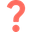
Проанализируйте и изложите содержательный смысл полученных результатов.

Найдены шесть пар мотивов для окна **165 часов** (6 суток 21 час), зона исключения — 83 отсчёта.

| Пара | Первое начало | Второе начало | Расстояние |
|---|---:|---:|---:|
| 1 | 17852 | 18188 | 1.226625 |
| 2 | 18539 | 27276 | 1.235633 |
| 3 | 19168 | 28073 | 1.245558 |
| 4 | 18623 | 18791 | 1.325500 |
| 5 | 17764 | 26837 | 1.348673 |
| 6 | 1020 | 9757 | 1.375152 |

Первая пара разделена 336 часами, то есть двумя неделями. У четвёртой пары разница равна 168 часам — одной неделе. Это согласуется с повторяемостью недельной формы потребления. Нормализованные расстояния сравнивают форму, поэтому сами по себе не доказывают совпадения уровня нагрузки или причины сезонности.


### **Задача 3.**
Реализуйте самостоятельно функцию `top_k_discords()` в модуле *discords.py*, предназначенную для поиска top-$k$ диссонансов во временном ряде на основе матричного профиля. Чтобы исключить попадание тривиальных совпадений в результирующее множество диссонансов воспользуйтесь функцией `apply_exclusion_zone()` из модуля *utils.py*.

Загрузите временной ряд *nyc_taxi.csv* из директории *./datasets/part1/*, содежащий данные о среднем числе пассажиров NY такси за осень 2014 года.

In [12]:
ts_url = './datasets/part1/nyc_taxi.csv'

ts = pd.read_csv(ts_url, index_col=0, header=0).squeeze().to_numpy()
plot_ts(ts, "Input time series")

In [13]:
m = 96
excl_zone = int(np.ceil(m / 2))
mp = {}

# INSERT YOUR CODE
mp = compute_mp(ts.astype(np.float64), m, excl_zone)
taxi_mp = mp

In [14]:
top_k = 15
discords = {}

# INSERT YOUR CODE
discords = top_k_discords(mp, top_k)
discords
taxi_discords = discords

Выполните визуализацию найденных top-$k$ диссонансов.

In [15]:
plot_discords(mp, discords)

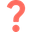
Проанализируйте и изложите содержательный смысл полученных результатов.

Найдены **15 диссонансов** с окном **96 получасовых отсчётов — двое суток** и зоной исключения 48 отсчётов. Самый выраженный диссонанс начинается в позиции **9985**, расстояние до ближайшего нетривиального соседа — **7.676119**.

Большие значения профиля означают необычную форму двухсуточного фрагмента относительно остальных окон ряда. На графике выделены как области около конца ряда, так и другие локальные отклонения. Это основание для изучения исходных дат, но без внешних данных нельзя приписывать отклонения праздникам или погоде.

Заданная зона исключения применяется при вычислении профиля и выборе результатов. Она исключает близкие начала окон, но не требует полной непересекаемости двухсуточных интервалов.

## **Часть 2.** Сегментация повторяющихся активностей.

### **Задача 4.**

Загрузите временной ряд PAMAP *pamap.csv* из директории *./datasets/part2/*, представляющий собой показания закрепленного на человеке виброакселерометра. Данный ряд включает показания, снятые при выполнении человеком трех видов физической активности: ходьба, подъем по лестнице и спуск по лестнице. Необходимо сегментировать временной ряд на основе его матричного профиля для определения того, когда человек шел и когда поднимался/спускался. Поскольку подъем и спуск по лестнице – это схожие действия, поэтому будем считать, что это одна активность.  

In [16]:
ts_url = './datasets/part2/pamap.csv'

ts = pd.read_csv(ts_url, header=None).squeeze().to_numpy()

Визуализируйте временной ряд PAMAP.

In [17]:
plot_ts(ts, "Input time series")

Найдите и визуализируйте матричный профиль временного ряда.

In [18]:
m = 100
excl_zone = m
mp = compute_mp(ts, m, excl_zone)
pamap_mp = mp

In [19]:
plot_ts(mp['mp'], "Matrix Profile")

Вычислите порог по формуле, которая представлена в презентации [04 Matrix profile.pdf](https://github.com/mzym/TimeSeriesCourse/blob/main/slides/04%20Matrix%20profile.pdf).

In [20]:
alpha = 0.5
finite = np.isfinite(mp['mp'])
assert finite.any(), 'Нет конечных значений матричного профиля'
threshold = alpha * (mp['mp'][finite].min() + mp['mp'][finite].max())
predicted_stairs = mp['mp'] < threshold
print(f'Порог: {threshold:.6f}; alpha = {alpha}')

Порог: 6.246194; alpha = 0.5


Выполните визуализацию результатов сегментации повторяющихся активностей.

In [21]:
plot_segmentation(mp, threshold)

Загрузите истинную разметку временного ряда PAMAP *pamap_labels.csv*, где 0 означает ходьбу, 1 – подъем по лестнице, 2 – спуск с лестницы. Вычислите точность по метрике accuracy, сравнив полученные результаты по основе матричного профиля с истинной разметкой.

In [22]:
labels_url = './datasets/part2/pamap_labels.csv'

labels = pd.read_csv(labels_url, header=None).squeeze().to_numpy()

In [23]:
centers = np.arange(len(mp['mp'])) + m // 2
true_stairs = labels[centers] != 0
accuracy = np.mean(predicted_stairs[finite] == true_stairs[finite])
print(f'Accuracy: {accuracy:.4%}')
print(f'Оценено окон: {finite.sum()}; исключено: {(~finite).sum()}')
segmentation_results = pd.DataFrame({
    'Центр окна': centers[finite],
    'Лестница: истинная метка': true_stairs[finite],
    'Лестница: прогноз': predicted_stairs[finite],
})
display(pd.crosstab(segmentation_results['Лестница: истинная метка'],
                    segmentation_results['Лестница: прогноз']))

Accuracy: 94.6679%
Оценено окон: 30401; исключено: 500


Лестница: прогноз,False,True
Лестница: истинная метка,,
False,10209,582
True,1039,18571


**Результат сегментации.** При `alpha=0.5`, выбранном заранее, порог равен **6.246194**, accuracy — **94.6679%**. Метки подъёма и спуска объединены в класс «лестница»; ходьба — второй класс.

Оценены **30401** окон по метке в центре каждого окна. Исключены **500** окон с неконечным профилем: в исходном PAMAP есть пять пропусков. Значения данных не заполнялись. Последние точки ряда не дополнялись искусственными предсказаниями. Большая часть участков лестницы выделена, ошибки концентрируются у переходов и кратких выбросов профиля.

## **Чaсть 3.** Casy Study: Раскрытие краж электричества подменой счетчиков (meter-swapping detection).


### **Задача 5.**

Рассмотрим практическое применение использования матричного профиля для решения задачи, связанной с раскрытием краж электричества путем подмены счетчиков.

Загрузите временные ряды из директории *./datasets/part3/*, которые были выбраны случайным образом из набора данных (House 1, 2, 3, 4 и 11), содержащего данные потребления электроэнергии 20 жилых домов в Великобритании с 1 января по 23 декабря 2014 года.

In [24]:
path = './datasets/part3/'

house_idx = [1, 2, 3, 4, 11]

filenames = [f"House{i}.csv" for i in house_idx]

consumptions = {}
for house in filenames:
    consumptions[house[:-4]] = pd.read_csv(os.path.join(path, house), header=None, index_col=0)
    consumptions[house[:-4]].index = pd.to_datetime(consumptions[house[:-4]].index, format='ISO8601')

Далее смоделируем событие замены счетчика. Для этого каждый временной ряд разделим на две части: "Head" (до 1 октября) и "Tail" (после 1 октября). После чего выберем случайным образом 2 временных ряда (например, House1 и House11) и поменяем местами их "Tail" части.

In [25]:
cutoff = pd.to_datetime('2014-10-01')
heads, tails = heads_tails(consumptions, cutoff, house_idx)

#swap Heads and Tails of 1 and 11
swap1, swap2 = 1, 11
consumptions[f'House{swap1}'] = pd.concat([heads[f'H_{swap1}'], tails[f'T_{swap2}']])
consumptions[f'House{swap2}'] = pd.concat([heads[f'H_{swap2}'], tails[f'T_{swap1}']])
heads, tails = heads_tails(consumptions, cutoff, house_idx)

Визуализируйте исходные временные ряды и параллельную оси OY прямую, которая делит временные ряды на "Head" и "Tail" части.

In [26]:
plot_consumptions_ts(consumptions, cutoff, house_idx)

Чтобы найти переставленную пару временных рядов, выполним следующее. Сначала составим временные ряды $H_i$ из всевозможных комбинаций "Head" и "Tail" частей исходных временных рядов $T_K$, где $1 \leq i \leq |T|^2$, $1 \leq K \leq |T|$. В нашем случае, $|T| = 5$.  Далее среди них найдем такую пару временных рядов $(H_i, H_j)$, которая имеет минимальную оценку $swap\_score$. Минимальная оценка $swap\_score$ для пары рядов $(H_i, H_j)$ вычисляется следующим образом:

\begin{equation}
swap\_score(i,j) = \frac{\min{(Head_{H_i} \bowtie Tail_{H_j})}}{\min{(Head_{H_i} \bowtie Tail_{H_i})}+eps},
\end{equation}

где $\bowtie$ – операция нахождения матричного профиля между двумя временными рядами. Матричный профиль между двумя временными рядами содержит расстояния между всеми подпоследовательностями первого временного ряда и их ближайшими соседями, которые являются подпоследовательностями второго временного ряда.

Добавьте в функцию `compute_mp()` в модуле *mp.py* поддежку вычисления матричного профиля между двумя различными временными рядами и найдите пару временных рядов $(H_i, H_j)$, которая имеет минимальную оценку $swap\_score$ среди всех пар.

In [27]:
m = 24 * 4

min_score = meter_swapping_detection(heads, tails, house_idx, m)

In [28]:
min_i, min_j, mp_j = min_score['i'], min_score['j'], min_score['mp_j']
print(f'Time series with minimum score is (H_{min_i}, T_{min_j}).')
print(f"Swap score: {min_score['score']:.6f}")
print(f'Смоделированная подмена: House{swap1} и House{swap2}')
print(f'Совпала ли найденная пара: {set([min_i, min_j]) == set([swap1, swap2])}')

Time series with minimum score is (H_11, T_1).
Swap score: 0.507818
Смоделированная подмена: House1 и House11
Совпала ли найденная пара: True


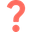
Проанализируйте и изложите содержательный смысл полученных результатов.

Минимальная оценка получена для **Head дома 11 и Tail дома 1**: `swap_score = 0.507818`. Это верно определяет смоделированную подмену между домами **1 и 11**.

Проверены 20 направленных пар разных домов. Для знаменателей отдельно вычислены пять профилей собственных Head–Tail. Использованы нормализованные расстояния между окнами длиной 96 часов; минимум берётся только по конечным значениям. Пропуски в записях сохранены.

Оценка меньше единицы означает, что найденная чужая хвостовая часть ближе к голове дома, чем его текущая собственная хвостовая часть. Результат подтверждает учебную модель подмены; сам по себе он не устанавливает факт кражи электроэнергии.

In [29]:
import json
from pathlib import Path

assert len(power_mp['mp']) == len(power_mp['data']['ts1']) - 165 + 1
assert len(power_motifs['indices']) == 6
assert len(taxi_discords['indices']) == 15
for profile in [power_mp, taxi_mp, pamap_mp]:
    valid = np.isfinite(profile['mp'])
    assert np.all(profile['mpi'][valid] >= 0)
    assert np.all(profile['mpi'][valid] < len(profile['mp']))
    assert np.all(np.abs(np.flatnonzero(valid) - profile['mpi'][valid]) > profile['excl_zone'])
assert len(segmentation_results) == finite.sum()
assert 0 <= accuracy <= 1
summary = {
    'power_motifs': power_motifs,
    'taxi_discords': taxi_discords,
    'segmentation': {'threshold': float(threshold), 'accuracy': float(accuracy),
                     'evaluated': int(finite.sum()), 'excluded': int((~finite).sum())},
    'swap': {k: v for k, v in min_score.items() if k != 'mp_j'},

}
Path('.cache/results.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2))
print('Проверки полного запуска пройдены')


Проверки полного запуска пройдены
